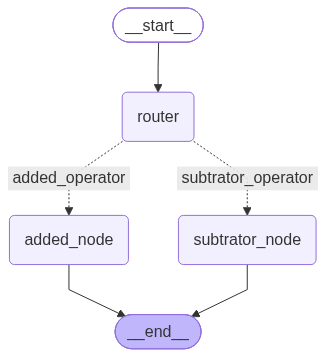

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END  # <-- 'langgraph' no existe dentro de langgraph.graph

class AgentState(TypedDict):
    name: int
    operation: str
    number: int
    finalnumber: int



def added_operator(state: AgentState) -> AgentState: 
    state['finalnumber'] = state['name'] + state['number']
    return state


def subtrator_operator(state: AgentState) -> AgentState:
    return state



def next(state: AgentState) -> AgentState:

    if state['operation'] == '+':
        return 'added_operator' 
    
    if state['operation'] == '-':
        return 'subtrator_operator'


graph = StateGraph[AgentState, None, AgentState, AgentState](AgentState)  
graph.add_node('added_node',added_operator)
graph.add_node('subtrator_node',subtrator_operator)
graph.add_node('router', lambda state:state)

graph.add_conditional_edges('router',next,{'added_operator':"added_node","subtrator_operator":"subtrator_node"})

graph.add_edge(START, 'router')

app = graph.compile()

from IPython.display import Image, display

# Obtiene la definición en texto Mermaid
mermaid_code = app.get_graph().draw_mermaid()

# Lo renderiza directamente en Jupyter
png_data = app.get_graph().draw_mermaid_png(max_retries=5, retry_delay=2.0)
display(Image(png_data))

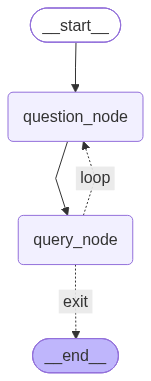

In [38]:
from typing import Literal
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display


# 1. Definición del Estado
class AgentStateLoop(TypedDict):
    name: str
    lastname: str
    number: int


# 2. Definición de Nodos
def questionsNode(state: AgentStateLoop) -> AgentStateLoop:
    return state


def queryNodes(state: AgentStateLoop) -> AgentStateLoop:
    # Mutar directamente o retornar un dict parcial
    return {"number": state.get("number", 0) + 1}


# Función condicional (determina la ruta, devuelve un literal/str)
def should_continue(state: AgentStateLoop) -> Literal["loop", "exit"]:
    if state["number"] < 5:
        return "loop"
    return "exit"


# 3. Construcción del Grafo
builder = StateGraph(AgentStateLoop)
# Agregar nodos
builder.add_node("question_node", questionsNode)
builder.add_node("query_node", queryNodes)

# Definir flujo
builder.add_edge(START, 'question_node')
builder.add_edge("question_node", "query_node")

builder.add_conditional_edges('query_node',should_continue,{"loop":"question_node", "exit":END})

appLoop = builder.compile()

# 4. Renderizado
png_data = appLoop.get_graph().draw_mermaid_png(max_retries=5, retry_delay=2.0)
display(Image(png_data))

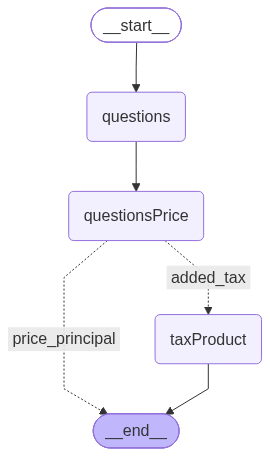

In [ ]:
from typing import Literal
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END


class AgentSaleforce(TypedDict):
    product: str
    price: int
    cant: int
    tax: int
    total: int


def questionsProduct(state: AgentSaleforce) -> AgentSaleforce:
    state["product"] = "the product is rice"
    return state


def questionsPrice(state: AgentSaleforce) -> AgentSaleforce:
    state["price"] = 23
    return state


def discountProduct(
    state: AgentSaleforce
) -> Literal["added_tax", "price_principal"]:

    if state["price"] < 23:
        return "added_tax"

    return "price_principal"


def taxProduct(state: AgentSaleforce) -> AgentSaleforce:
    state["tax"] = state["price"] * 0.15
    return state


graph = StateGraph[AgentSaleforce, None, AgentSaleforce, AgentSaleforce](AgentSaleforce)

graph.add_node("questions", questionsProduct)
graph.add_node("questionsPrice", questionsPrice)
graph.add_node("taxProduct", taxProduct)

graph.add_edge(START, "questions")
graph.add_edge("questions", "questionsPrice")

graph.add_conditional_edges(
    "questionsPrice",
    discountProduct,
    {
        "added_tax": "taxProduct",
        "price_principal": END
    }
)

graph.add_edge("taxProduct", END)

app = graph.compile()

# 4. Renderizado
png_data = app.get_graph().draw_mermaid_png(max_retries=5, retry_delay=2.0)
display(Image(png_data))